# Неделя 07. Data storytelling и очистка без потери смысла

        **Занятие 1:** как превратить график в проверяемое сообщение для руководителя.
        **Занятие 2:** как обнаружить пропуски, дубли, ошибки формата и редкие наблюдения,
        сохранив журнал решений. Все примеры синтетические.

        Итог — аккуратный аналитический вывод, исходные данные без изменений,
        очищенная копия и проверки того, что ни одна строка не исчезла незаметно.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json
import seaborn as sns

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 100})

def locate_week():
    "Работает из practice/, homework/, папки недели и корня репозитория."
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        for candidate in (parent, parent / 'week_07_storytelling_cleaning'):
            if candidate.name == 'week_07_storytelling_cleaning' and (candidate / "datasets").is_dir():
                return candidate
    raise FileNotFoundError("Откройте notebook внутри полного клона репозитория.")

WEEK_DIR = locate_week()
DATA_DIR = WEEK_DIR / "datasets"
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Рабочая неделя:", WEEK_DIR.name)


Python: 3.12.14 | NumPy: 2.5.4 | pandas: 3.0.6
Рабочая неделя: week_07_storytelling_cleaning


## 1. Storytelling начинается с решения, которое предстоит принять

        Аудитория: руководитель службы. Вопрос: уменьшилась ли доля обращений с долгим ожиданием?
        Нужна доля с прозрачным знаменателем, а не только абсолютное число задержек.
        Первые четыре строки ниже — отдельный демонстрационный агрегат; к грязной выгрузке июня
        они не относятся. Смешивать эти два источника в одном временном тренде нельзя.


In [2]:
monthly = pd.read_csv(DATA_DIR / "storytelling_monthly.csv")
monthly["over_60_share"] = monthly["over_60_n"] / monthly["requests_n"]
assert monthly["over_60_n"].le(monthly["requests_n"]).all()
display(monthly)


,month,requests_n,over_60_n,over_60_share
0,2026-01,120,36,0.30
1,2026-02,150,42,0.28
2,2026-03,180,45,0.25
3,2026-04,160,32,0.20


## 2. Абсолютное число и доля могут рассказывать разные истории

        На первом графике — нагрузка долгими обращениями. На втором — доля от всех обращений.
        Столбцы начинаются от нуля; подписи n показывают знаменатель. Заголовок сообщает,
        что именно измерено, без обещаний о причине изменения.


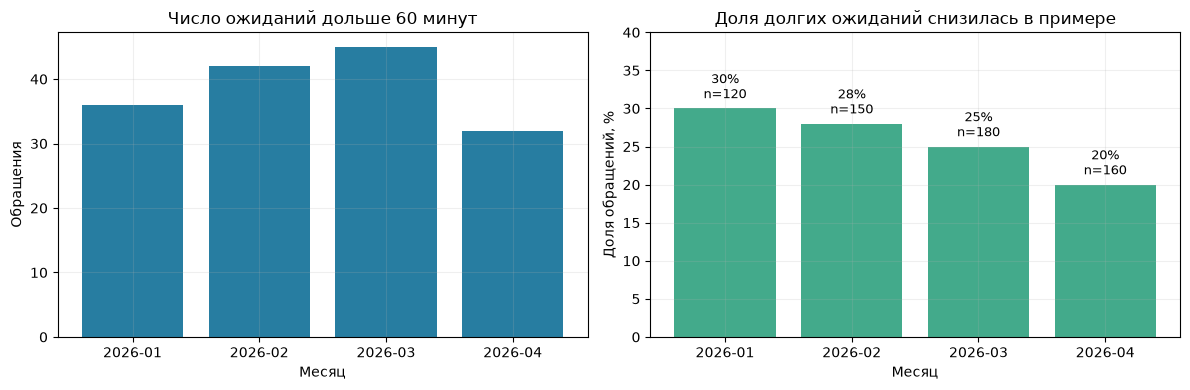

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(monthly["month"], monthly["over_60_n"], color="#277DA1")
axes[0].set(xlabel="Месяц", ylabel="Обращения", title="Число ожиданий дольше 60 минут")
bars = axes[1].bar(monthly["month"], monthly["over_60_share"] * 100, color="#43AA8B")
for bar, row in zip(bars, monthly.itertuples()):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
                 f"{row.over_60_share:.0%}\nn={row.requests_n}", ha="center", va="bottom", fontsize=9)
axes[1].set(xlabel="Месяц", ylabel="Доля обращений, %", ylim=(0, 40), title="Доля долгих ожиданий снизилась в примере")
plt.tight_layout()
plt.show()


## 3. Проценты и процентные пункты

        Падение с 30% до 20% — это −10 процентных пунктов, а относительное изменение равно −33,3%.
        Эти величины описывают одно изменение на разных шкалах. В выводе укажите, какая шкала используется.
        Мы описываем данные; чтобы объяснить причину, нужны сведения о нагрузке, персонале и процессе.


In [4]:
first = monthly.iloc[0]
last = monthly.iloc[-1]
change_pp = 100 * (last["over_60_share"] - first["over_60_share"])
relative_change = last["over_60_share"] / first["over_60_share"] - 1
print(f"В синтетическом примере доля снизилась с {first['over_60_share']:.0%} до {last['over_60_share']:.0%}.")
print(f"Изменение: {change_pp:.1f} п.п.; относительное изменение: {relative_change:.1%}.")
print("Причина не установлена; следующий шаг — проверить состав обращений и изменения процесса.")
assert np.isclose(change_pp, -10)


В синтетическом примере доля снизилась с 30% до 20%.
Изменение: -10.0 п.п.; относительное изменение: -33.3%.
Причина не установлена; следующий шаг — проверить состав обращений и изменения процесса.


## 4. Новая поставка: сначала аудит, затем очистка

        Загружаем сырую июньскую выгрузку как есть. Не перезаписываем её и не удаляем строки
        глобальным `dropna()`. Для каждого преобразования фиксируем, что оно изменяет и почему.
        Сначала удалим только точные повторы; конфликтующие записи одного ID потребовали бы разбора.


In [5]:
raw = pd.read_csv(DATA_DIR / "service_requests_dirty.csv")
original = raw.copy(deep=True)
rules = json.loads((DATA_DIR / "cleaning_rules.json").read_text(encoding="utf-8"))
display(raw.head())
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum()}))
exact_duplicates = int(raw.duplicated().sum())
clean_data = raw.drop_duplicates().copy()
assert exact_duplicates == 5 and len(clean_data) == 150
assert clean_data["request_id"].is_unique
audit_rows = [{"step": "raw", "rows": len(raw), "affected": 0},
              {"step": "remove_exact_duplicates", "rows": len(clean_data), "affected": exact_duplicates}]


,request_id,created_at,district,source,priority,status,response_minutes,cost_kzt
0,R0001,2026-06-01T08:00:00,center,mobile,high,open,34.1,NaN
1,R0002,2026-06-01T12:00:00,south,mobile,low,closed,101.2,5558
2,R0003,2026-06-01T16:00:00,north,phone,medium,closed,99.7,27998
3,R0004,2026-06-01T20:00:00,SOUTH,phone,medium,closed,58.6,20832
4,R0005,2026-06-02T00:00:00,center,phone,high,closed,30.5,13114


,dtype,missing
request_id,str,0
created_at,str,0
district,str,0
source,str,0
priority,str,0
status,str,0
response_minutes,str,21
cost_kzt,str,9


## 5. Ошибка формата и пропуск — разные причины неизвестности

        `errors='coerce'` превращает неразбираемые значения в missing, но важно сохранить флаг причины.
        Отрицательная стоимость по условию недопустима; нулевая допустима.
        Неположительное время ответа недопустимо. Большое положительное время не является ошибкой само по себе.


In [6]:
for column in ["response_minutes", "cost_kzt"]:
    parsed = pd.to_numeric(clean_data[column], errors="coerce")
    clean_data[column + "_parse_error"] = clean_data[column].notna() & parsed.isna()
    clean_data[column + "_was_missing"] = clean_data[column].isna()
    clean_data[column] = parsed

clean_data["invalid_cost"] = clean_data["cost_kzt"].lt(0)
clean_data["invalid_response"] = clean_data["response_minutes"].le(0)
clean_data.loc[clean_data["invalid_cost"], "cost_kzt"] = np.nan
clean_data.loc[clean_data["invalid_response"], "response_minutes"] = np.nan
parsed_dates = pd.to_datetime(clean_data["created_at"], errors="coerce")
clean_data["invalid_created_at"] = parsed_dates.isna()
clean_data["created_at"] = parsed_dates
flag_columns = [c for c in clean_data if c.endswith("_parse_error") or c.startswith("invalid_")]
display(clean_data[flag_columns].sum().to_frame("affected_rows"))
audit_rows.append({"step": "parse_and_flag_invalid", "rows": len(clean_data),
                   "affected": int(clean_data[flag_columns].any(axis=1).sum())})


,affected_rows
response_minutes_parse_error,1
cost_kzt_parse_error,1
invalid_cost,2
invalid_response,1
invalid_created_at,1


## 6. Нормализация категорий не должна угадывать смысл

        Убираем пробелы и приводим регистр, затем сопоставляем с явным словарём.
        Неизвестные значения нужно показать отдельно, а не автоматически относить к популярной группе.
        Сохраняем исходное написание для проверки преобразования.


In [7]:
clean_data["district_raw"] = clean_data["district"]
normalized = clean_data["district"].str.strip().str.lower()
district_map = {"center": "Center", "north": "North", "south": "South"}
clean_data["district"] = normalized.map(district_map)
assert clean_data["district"].notna().all()
display(clean_data[["district_raw", "district"]].drop_duplicates().sort_values("district"))
assert set(clean_data["district"]) == {"Center", "North", "South"}


,district_raw,district
0,center,Center
14,Center,Center
18,CENTER,Center
2,north,North
6,North,North
10,NORTH,North
1,south,South
3,SOUTH,South
8,South,South


## 7. Пропуски изучаем по источнику

        Доля missing может различаться по способу сбора данных. Это предупреждает,
        что анализ только полных строк способен изменить состав выборки.
        По одной таблице нельзя надёжно определить механизм MCAR/MAR/MNAR; здесь описываем наблюдаемое.


,requests,missing_n,missing_share,observed_n
source,,,,
mobile,46,4,0.087,42
phone,50,13,0.260,37
web,54,6,0.111,48


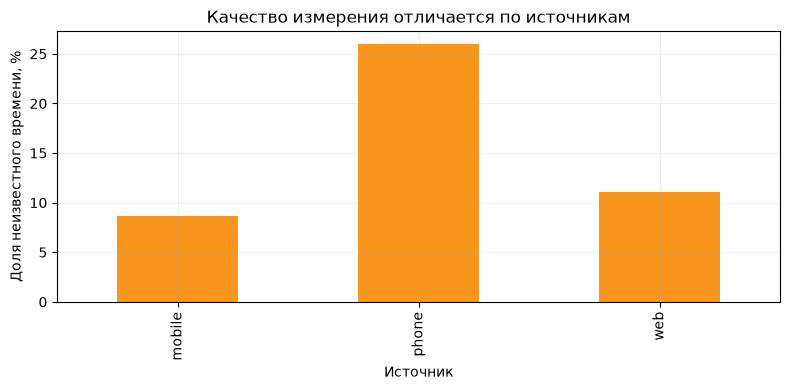

In [8]:
clean_data["response_missing"] = clean_data["response_minutes"].isna()
missing_by_source = clean_data.groupby("source").agg(
    requests=("request_id", "size"), missing_n=("response_missing", "sum"),
    missing_share=("response_missing", "mean"), observed_n=("response_minutes", "count"))
display(missing_by_source.round(3))
assert (missing_by_source["requests"] == missing_by_source["missing_n"] + missing_by_source["observed_n"]).all()
ax = (missing_by_source["missing_share"] * 100).plot.bar(color="#F8961E")
ax.set(xlabel="Источник", ylabel="Доля неизвестного времени, %", title="Качество измерения отличается по источникам")
plt.tight_layout()
plt.show()


## 8. IQR — флаг для проверки, не автоматическое удаление

        $IQR=Q_{0.75}-Q_{0.25}$. Обычная эвристика отмечает $x<Q_1-1.5IQR$ или $x>Q_3+1.5IQR$.
        Она не знает бизнес-смысла. В условии этого набора 2200 минут — допустимое редкое ожидание.
        Сохраняем его и сравниваем устойчивую медиану со средним. Порог вычислен для EDA всей выгрузки;
        в ML обучаемые пороги должны оцениваться только по train.


In [9]:
observed = clean_data["response_minutes"].dropna()
q1, q3 = observed.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
clean_data["response_iqr_flag"] = (clean_data["response_minutes"] < low) | (clean_data["response_minutes"] > high)
display(clean_data.loc[clean_data["response_iqr_flag"], ["request_id", "response_minutes", "source", "district"]])
assert clean_data.loc[clean_data["request_id"].eq("R0078"), "response_minutes"].iloc[0] == 2200
assert clean_data.loc[clean_data["request_id"].eq("R0078"), "response_iqr_flag"].iloc[0]
print(f"Среднее {observed.mean():.1f} мин; медиана {observed.median():.1f} мин; флагов {clean_data['response_iqr_flag'].sum()}.")


,request_id,response_minutes,source,district
77,R0078,2200.0,web,South


Среднее 72.5 мин; медиана 56.1 мин; флагов 1.


## 9. Честный отчёт по районам

        Для медианы используем доступные измерения; рядом указываем все обращения и число наблюдений.
        Неизвестное время не приравниваем к нулю и не считаем быстрым ответом.
        График на общей оси показывает медиану, а подписи n раскрывают покрытие измерениями.


,all_requests,observed_n,mean_minutes,median_minutes,p90_minutes,coverage
district,,,,,,
Center,57,50,39.96,41.45,61.70,0.88
North,50,42,56.99,56.75,86.24,0.84
South,43,35,137.53,76.20,103.46,0.81


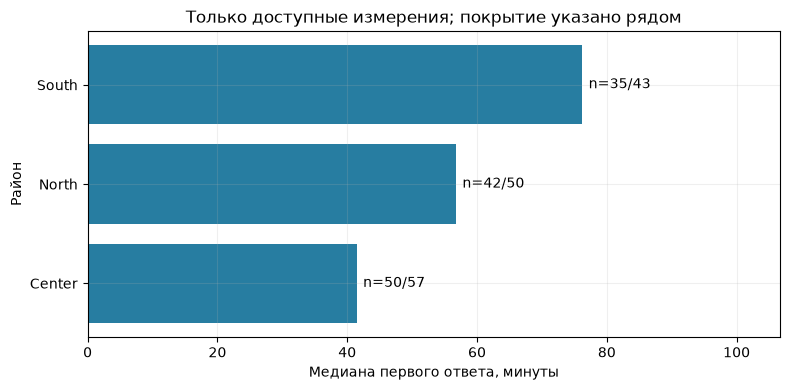

In [10]:
district_report = clean_data.groupby("district").agg(
    all_requests=("request_id", "size"), observed_n=("response_minutes", "count"),
    mean_minutes=("response_minutes", "mean"), median_minutes=("response_minutes", "median"),
    p90_minutes=("response_minutes", lambda s: s.quantile(0.9)))
district_report["coverage"] = district_report["observed_n"] / district_report["all_requests"]
display(district_report.round(2))
ordered = district_report.sort_values("median_minutes")
fig, ax = plt.subplots()
bars = ax.barh(ordered.index, ordered["median_minutes"], color="#277DA1")
for bar, (_, row) in zip(bars, ordered.iterrows()):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            f"n={int(row['observed_n'])}/{int(row['all_requests'])}", va="center")
ax.set(xlabel="Медиана первого ответа, минуты", ylabel="Район",
       title="Только доступные измерения; покрытие указано рядом")
ax.set_xlim(0, ordered["median_minutes"].max() * 1.4)
plt.tight_layout()
plt.show()


## 10. Импутация меняет данные, поэтому проверяем чувствительность

        Замена пропусков медианой может быть полезной инженерной операцией, но не восстанавливает
        реально измеренное значение. Покажем два сценария заполнения и сравним число наблюдений,
        среднее и разброс. Они не становятся двумя независимыми исследованиями.
        Исходный очищенный столбец оставим с пропусками.


In [11]:
available = clean_data["response_minutes"]
global_fill = available.fillna(available.median())
source_medians = clean_data.groupby("source")["response_minutes"].transform("median")
source_fill = available.fillna(source_medians)
sensitivity = pd.DataFrame({
    name: {"n_values": values.count(), "mean": values.mean(), "median": values.median(), "std": values.std(ddof=1)}
    for name, values in {"observed_only": available, "global_median_fill": global_fill,
                         "source_median_fill": source_fill}.items()
}).T
display(sensitivity.round(2))
assert available.isna().sum() == clean_data["response_missing"].sum()
print("Импутация показана как анализ чувствительности; очищенный исходник не заполнен.")


,n_values,mean,median,std
observed_only,127.0,72.48,56.1,191.84
global_median_fill,150.0,69.97,56.1,176.52
source_median_fill,150.0,69.39,52.4,176.58


Импутация показана как анализ чувствительности; очищенный исходник не заполнен.


## 11. Проверяем контракт и журнал решений

        Проверки должны защищать смысл: ключи уникальны, данные не потеряны, допустимый редкий случай
        сохранён, причины неизвестных значений не исчезли, оригинал не изменился.
        В финальном отчёте нельзя скрывать, что некоторые даты и значения остались неизвестными.


In [12]:
pd.testing.assert_frame_equal(raw, original)
assert clean_data["request_id"].is_unique and len(clean_data) == len(raw) - exact_duplicates
assert clean_data["cost_kzt"].dropna().ge(0).all()
assert clean_data["response_minutes"].dropna().gt(0).all()
assert clean_data["invalid_cost"].sum() == 2
assert clean_data["invalid_created_at"].sum() == 1
assert clean_data["response_minutes_parse_error"].sum() == 1
assert clean_data["cost_kzt_parse_error"].sum() == 1
assert district_report["all_requests"].sum() == len(clean_data)
audit_rows.append({"step": "final_clean_copy_with_flags", "rows": len(clean_data),
                   "affected": int(clean_data["response_missing"].sum())})
display(pd.DataFrame(audit_rows))
print("Контракт выполнен; исходный CSV не изменён.")


,step,rows,affected
0,raw,155,0
1,remove_exact_duplicates,150,5
2,parse_and_flag_invalid,150,6
3,final_clean_copy_with_flags,150,23


Контракт выполнен; исходный CSV не изменён.


## 12. Итоговая записка: что известно и чего не хватает

        Укажите число удалённых точных дублей, долю известного времени, медианы по районам
        и роль редкого ожидания 2200 минут. Предложите проверку процесса сбора в phone-канале.
        Не делайте вывод, что район или канал сам по себе вызывает задержку.

        Домашняя работа: [Homework Week 07](../homework/Homework_Week_07.md).


## Документация и дальнейшее чтение

- [pandas: missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html)
- [pandas: duplicates](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html)
- [pandas: to_numeric](https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html)
- [seaborn: распределения](https://seaborn.pydata.org/tutorial/distributions.html)

Код, объяснения и синтетические примеры в этой лабораторной подготовлены для курса; это не копия университетского ноутбука. Дополнительные лекции находятся в `../presentations/`. Документация проверена 18 октября 2026 года; версии среды закреплены на уровне репозитория.
